<a href="https://colab.research.google.com/github/Suthirtha2004/ChurnScope---Customer-Churn-Prediction/blob/main/Churn_Analysis_Using_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


Dataset Reading and Identifying Required Columns

In [2]:
data = pd.read_csv("/content/customer_data.csv")
print(data.head())
print(data.isnull().sum())

duplicate = data.duplicated()
print(f"Duplicated Data", duplicate)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
print(data.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [4]:
# Changing Datatype pf Total Charges and handles values
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"],errors="coerce")
print(data["TotalCharges"].isna().sum())
print(data["TotalCharges"].dtypes)
print(data.isna().sum())

data["TotalCharges"] = data['TotalCharges'].fillna(data['TotalCharges'].median())
print(data["TotalCharges"].isna().sum())



11
float64
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
0


In [5]:
data.replace('No internet service','No',inplace = True)

Generate Heatmap to get feature importance

In [6]:
import seaborn as sns

In [7]:
data['Churn_Encoded'] = data['Churn'].map({
    'No' : 0,
    'Yes' : 1
})
print(data.head(5))

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... TechSupport  \
0  No phone service             DSL             No  ...          No   
1                No             DSL            Yes  ...          No   
2                No             DSL            Yes  ...          No   
3  No phone service             DSL            Yes  ...         Yes   
4                No     Fiber optic             No  ...          No   

  StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No             

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen        1.000000  0.016567        0.220173      0.102652   
tenure               0.016567  1.000000        0.247900      0.825464   
MonthlyCharges       0.220173  0.247900        1.000000      0.650864   
TotalCharges         0.102652  0.825464        0.650864      1.000000   
Churn_Encoded        0.150889 -0.352229        0.193356     -0.199037   

                Churn_Encoded  
SeniorCitizen        0.150889  
tenure              -0.352229  
MonthlyCharges       0.193356  
TotalCharges        -0.199037  
Churn_Encoded        1.000000  


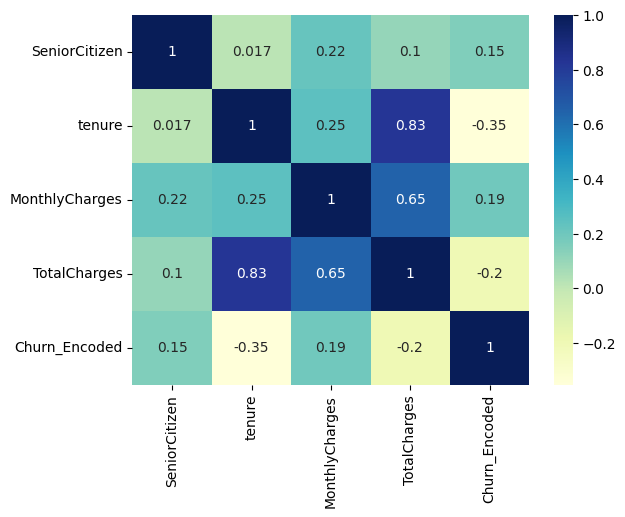

In [8]:
# Make correlation matrix
co_matrix = data.corr(numeric_only=True)
print(co_matrix)

#Plot correlation matrix
sns.heatmap(co_matrix,cmap ="YlGnBu",annot=True)

plt.show()

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges']


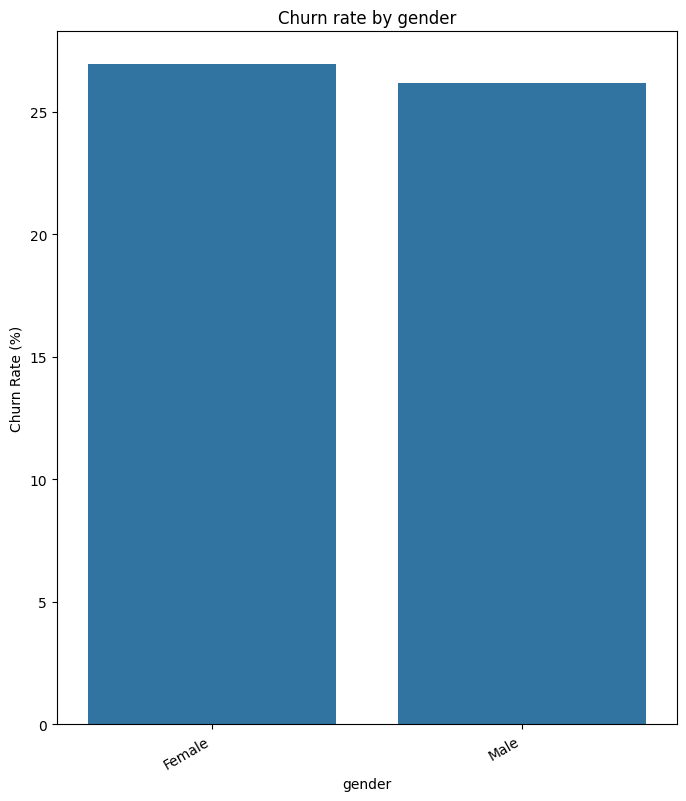

Churn rate :    gender  ChurnRate
0  Female  26.920872
1    Male  26.160338


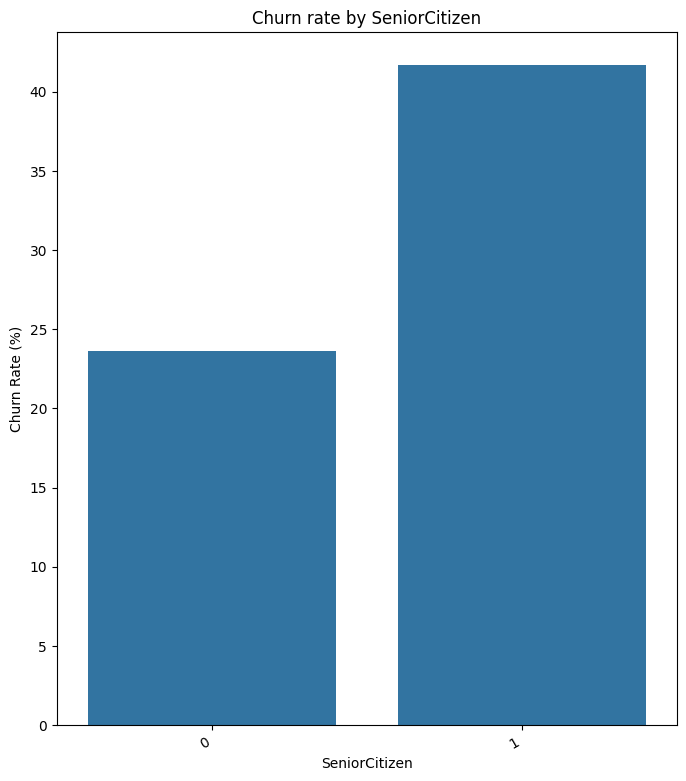

Churn rate :    SeniorCitizen  ChurnRate
0              0  23.606168
1              1  41.681261


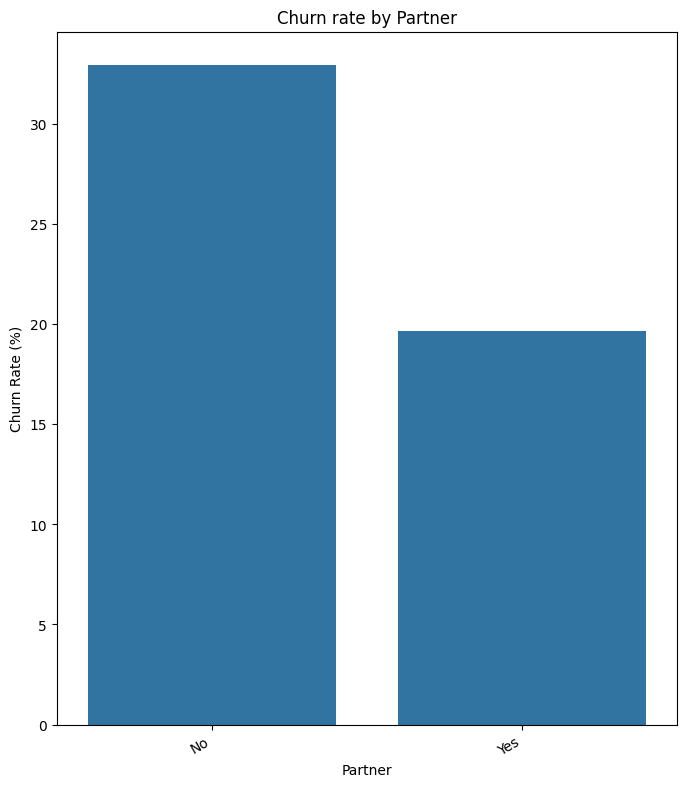

Churn rate :   Partner  ChurnRate
0      No  32.957979
1     Yes  19.664903


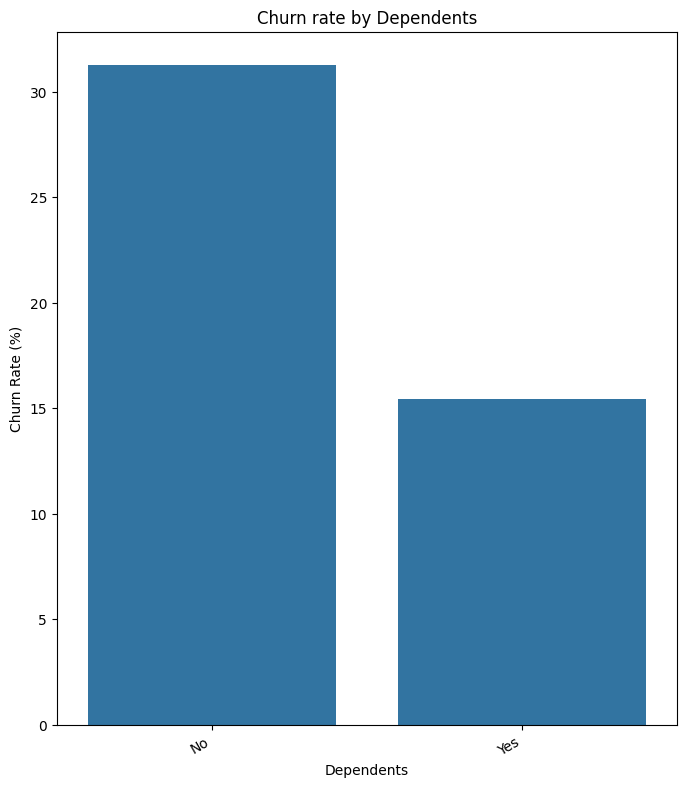

Churn rate :   Dependents  ChurnRate
0         No  31.279140
1        Yes  15.450237


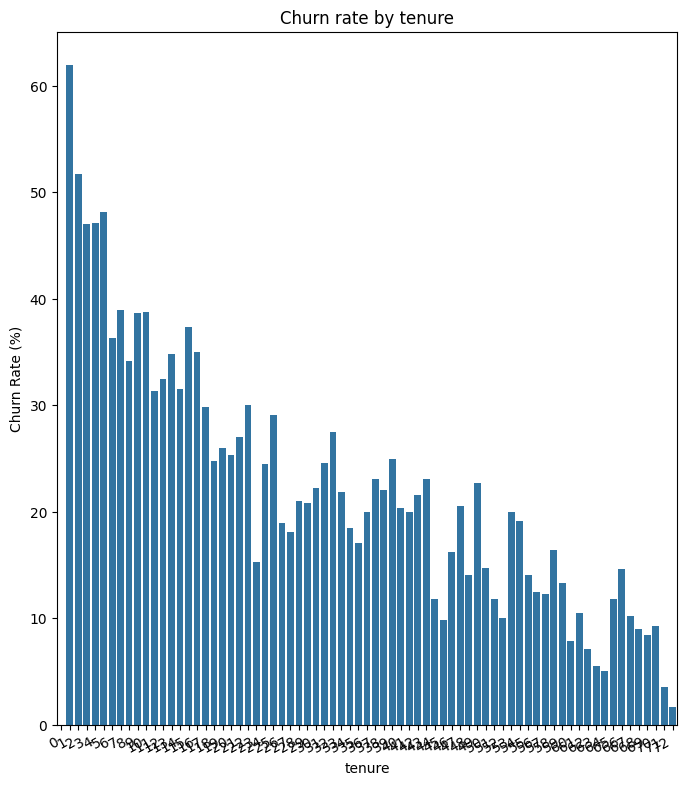

Churn rate :     tenure  ChurnRate
0        0   0.000000
1        1  61.990212
2        2  51.680672
3        3  47.000000
4        4  47.159091
..     ...        ...
68      68   9.000000
69      69   8.421053
70      70   9.243697
71      71   3.529412
72      72   1.657459

[73 rows x 2 columns]


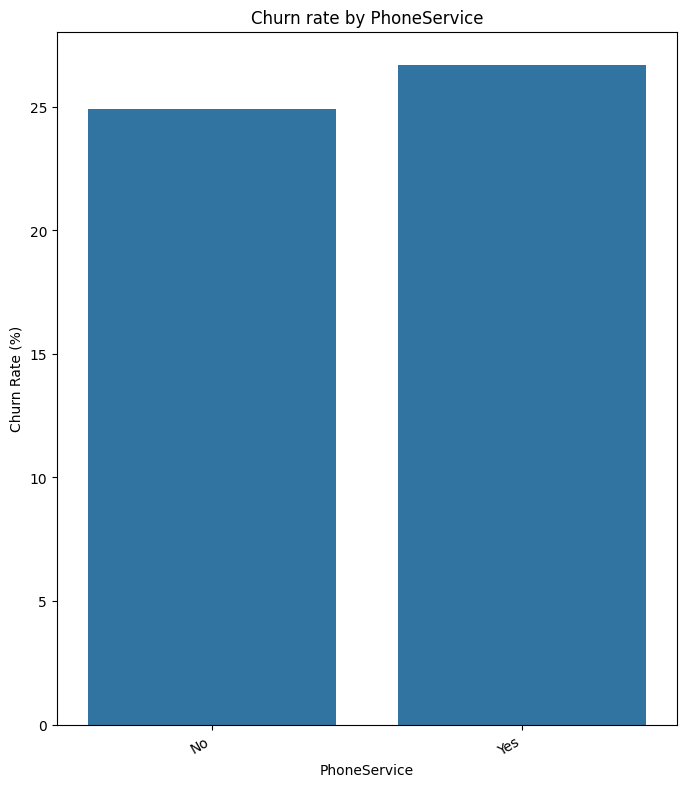

Churn rate :   PhoneService  ChurnRate
0           No  24.926686
1          Yes  26.709637


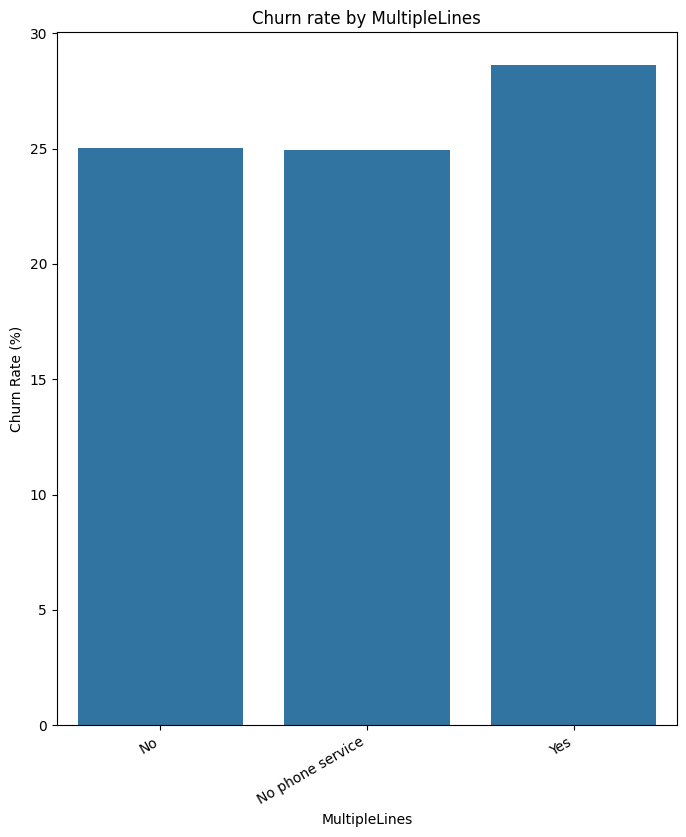

Churn rate :       MultipleLines  ChurnRate
0                No  25.044248
1  No phone service  24.926686
2               Yes  28.609896


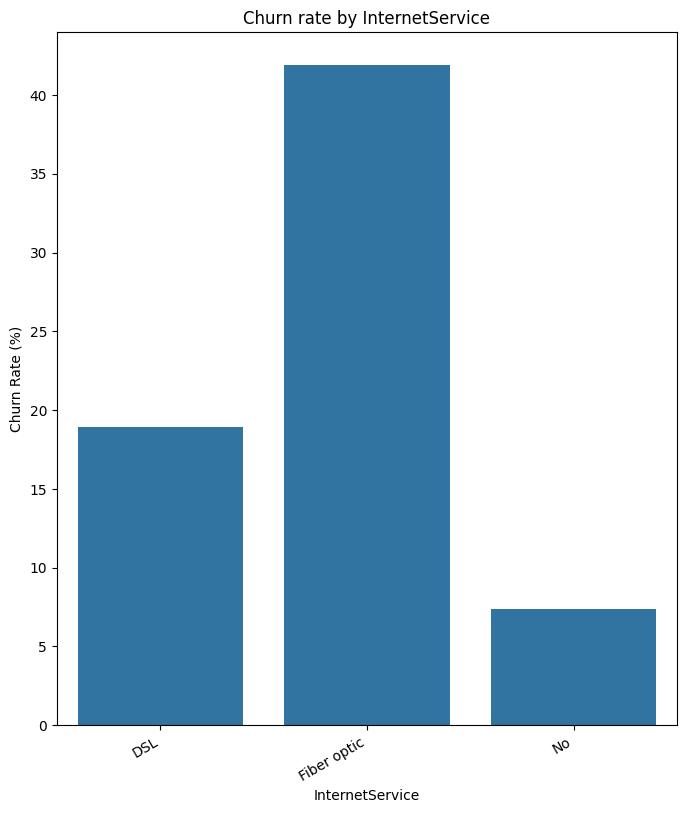

Churn rate :   InternetService  ChurnRate
0             DSL  18.959108
1     Fiber optic  41.892765
2              No   7.404980


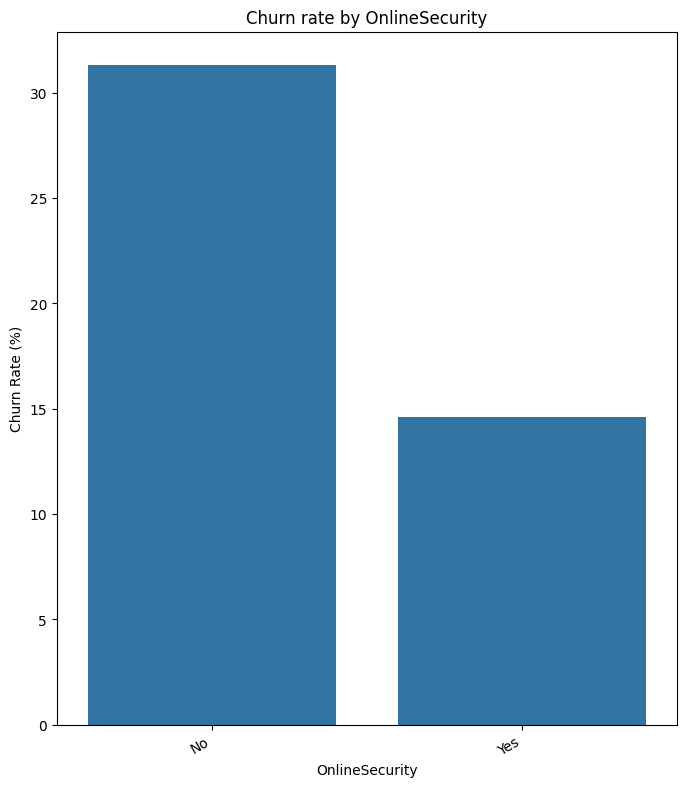

Churn rate :   OnlineSecurity  ChurnRate
0             No  31.329618
1            Yes  14.611194


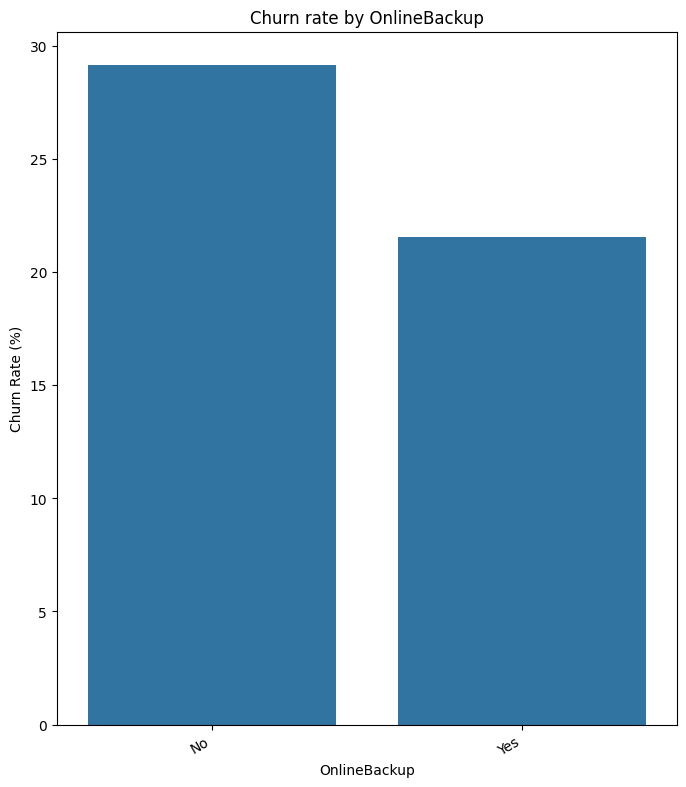

Churn rate :   OnlineBackup  ChurnRate
0           No  29.172085
1          Yes  21.531494


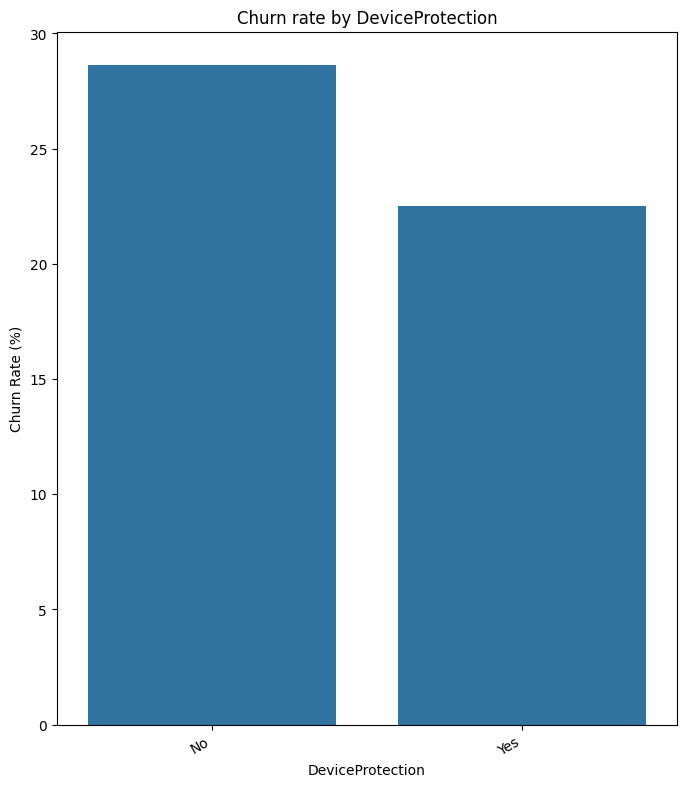

Churn rate :   DeviceProtection  ChurnRate
0               No  28.651807
1              Yes  22.502064


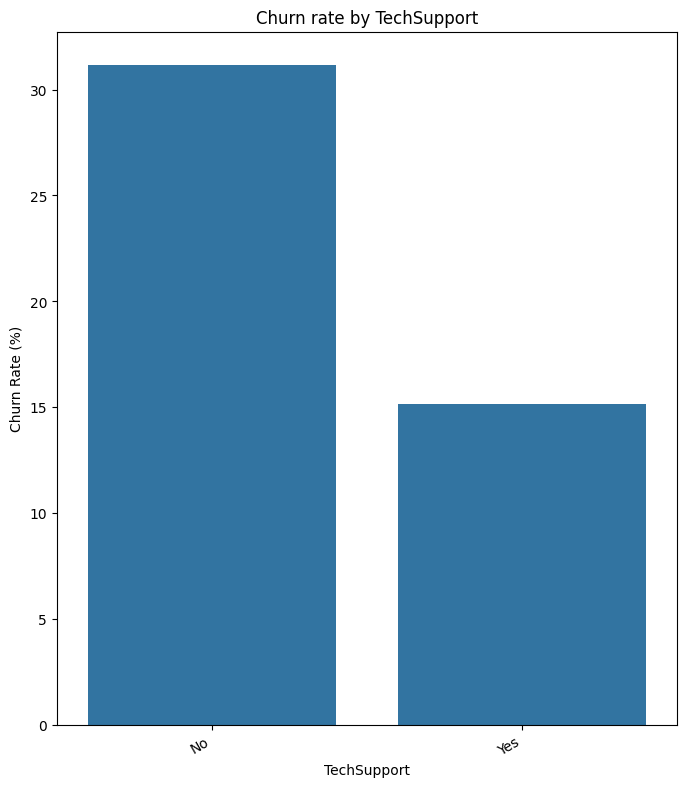

Churn rate :   TechSupport  ChurnRate
0          No  31.186237
1         Yes  15.166341


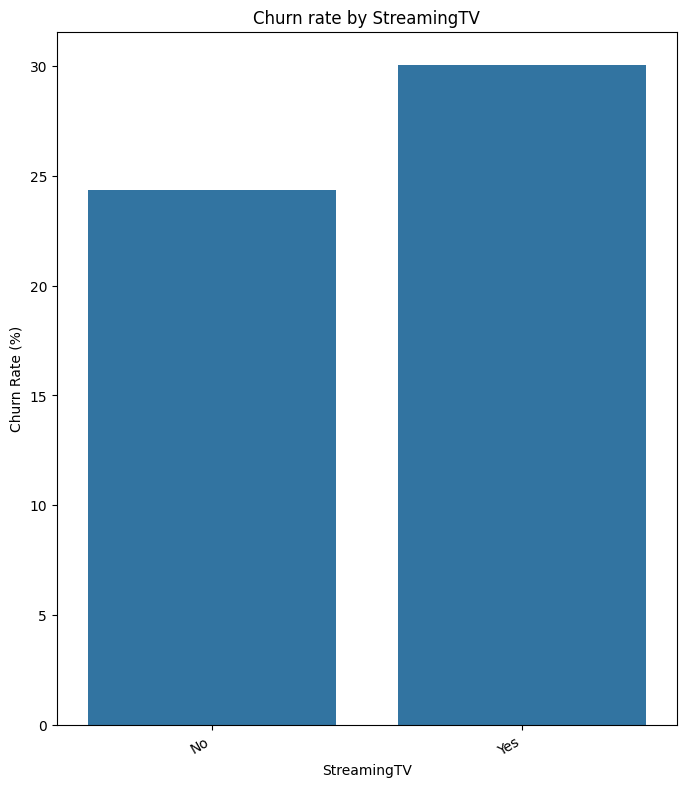

Churn rate :   StreamingTV  ChurnRate
0          No  24.331181
1         Yes  30.070188


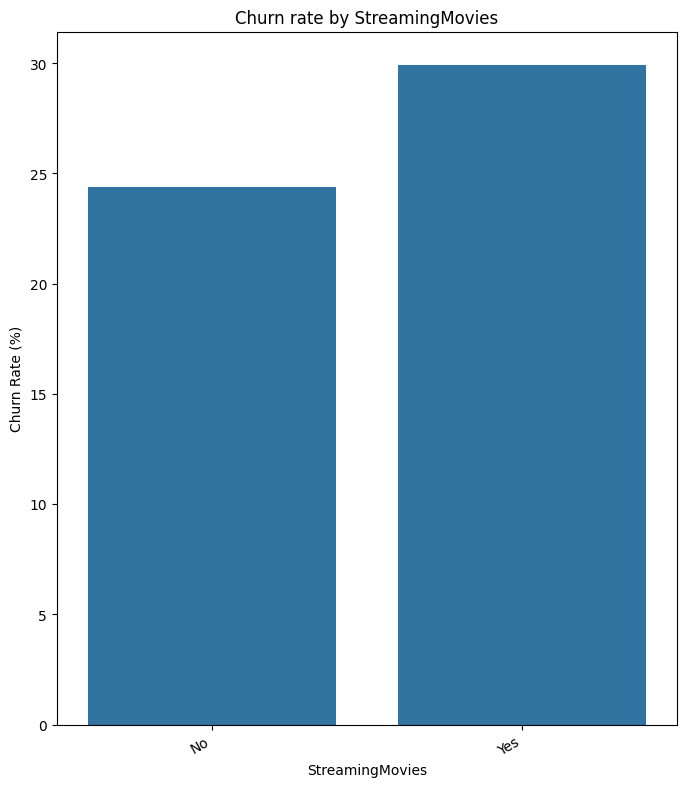

Churn rate :   StreamingMovies  ChurnRate
0              No  24.379494
1             Yes  29.941435


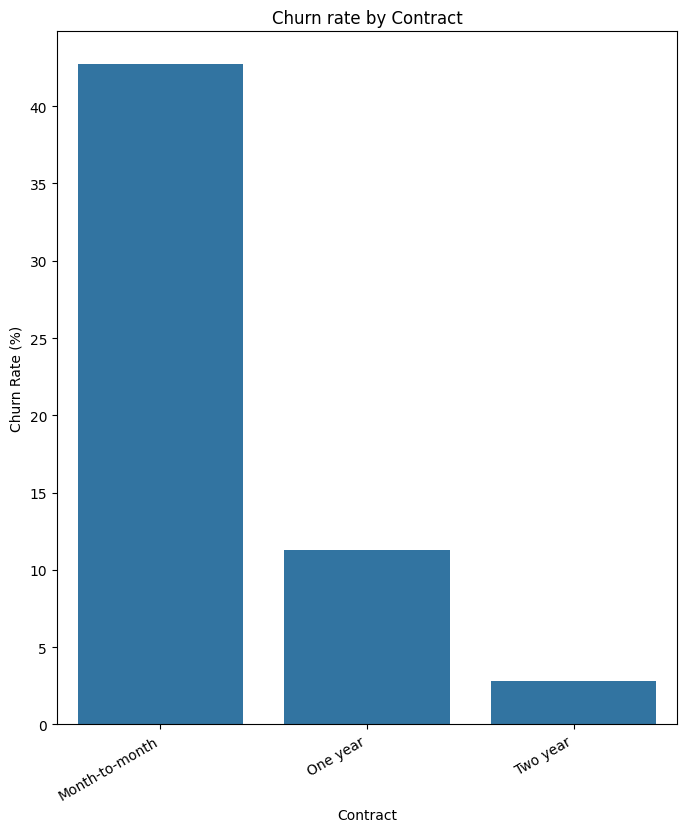

Churn rate :          Contract  ChurnRate
0  Month-to-month  42.709677
1        One year  11.269518
2        Two year   2.831858


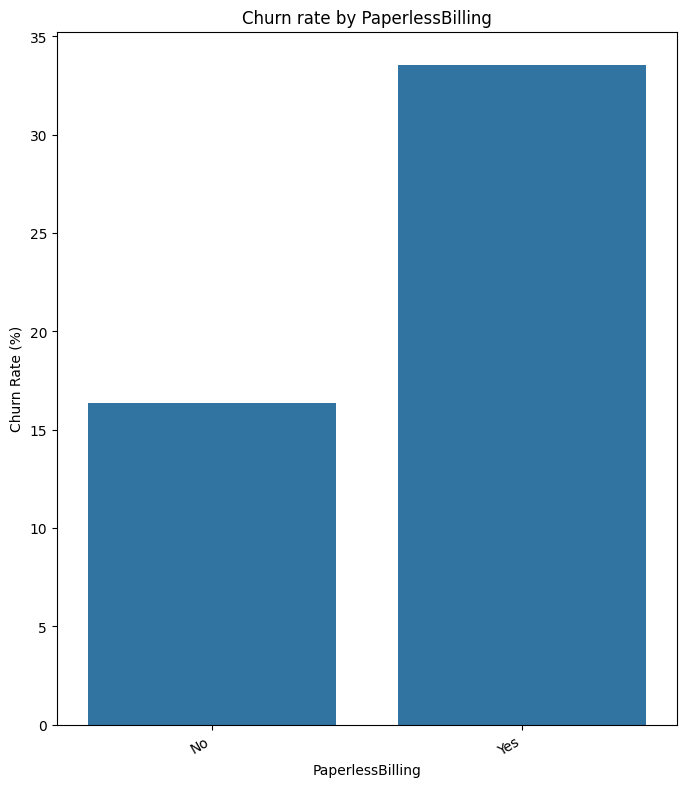

Churn rate :   PaperlessBilling  ChurnRate
0               No  16.330084
1              Yes  33.565092


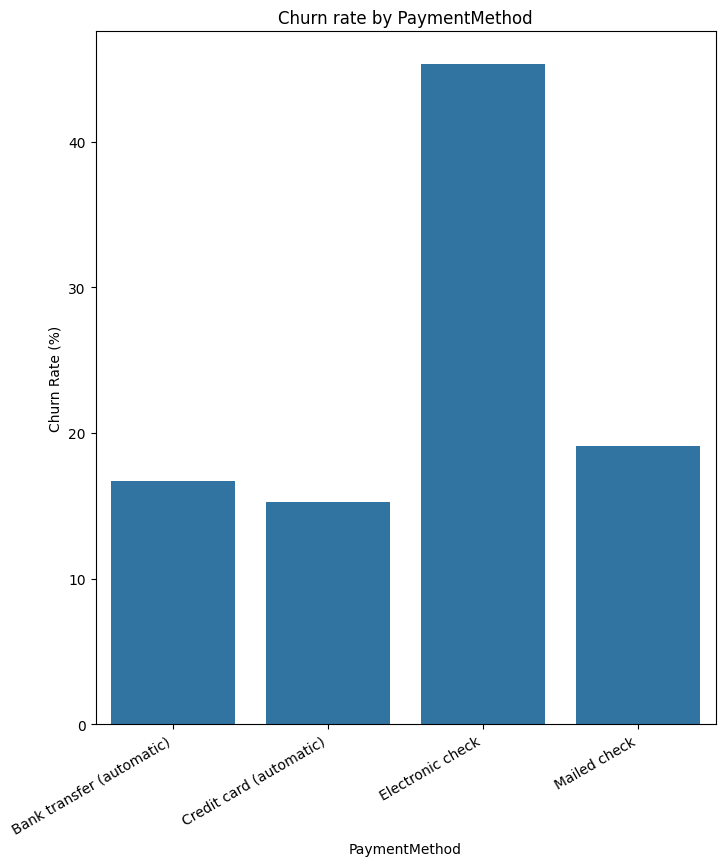

Churn rate :                PaymentMethod  ChurnRate
0  Bank transfer (automatic)  16.709845
1    Credit card (automatic)  15.243101
2           Electronic check  45.285412
3               Mailed check  19.106700


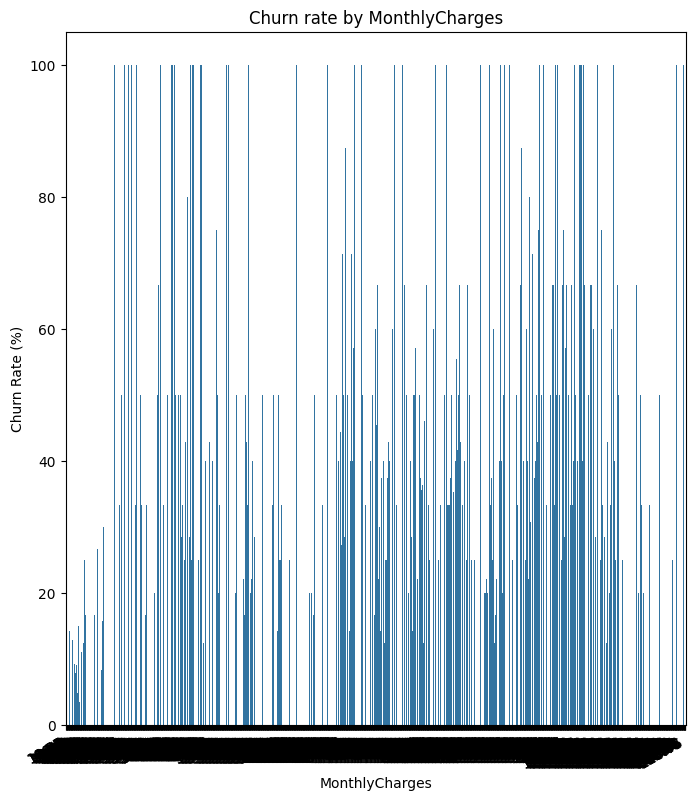

Churn rate :       MonthlyCharges  ChurnRate
0              18.25        0.0
1              18.40        0.0
2              18.55        0.0
3              18.70        0.0
4              18.75        0.0
...              ...        ...
1580          118.20        0.0
1581          118.35      100.0
1582          118.60        0.0
1583          118.65        0.0
1584          118.75        0.0

[1585 rows x 2 columns]


In [9]:
# Determination of Churn rate:

categorical_Cols = list(data.drop(columns=['customerID','TotalCharges','Churn','Churn_Encoded']))
print(categorical_Cols)

for col in categorical_Cols:

  churn_rate= (
      data.groupby(col,observed=True)["Churn_Encoded"]
      .mean()
      .mul(100)
      .reset_index(name="ChurnRate")
  )

  plt.figure(figsize=(8,9))
  sns.barplot(data=churn_rate,x=col,y="ChurnRate")
  plt.title(f"Churn rate by {col}")
  plt.ylabel("Churn Rate (%)")
  plt.xlabel(col)
  plt.xticks(rotation=30,ha="right")
  plt.tight_layout
  plt.show()
  print(f"Churn rate : {churn_rate}")

Using Logistic Regression


In [10]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_Encoded
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928,0.265370
std,0.368612,24.559481,30.090047,2265.270398,0.441561
min,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,9.000000,35.500000,402.225000,0.000000
50%,0.000000,29.000000,70.350000,1397.475000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


Use One-Hot encoding and Label-Encoding

In [11]:
data.replace("No phone service","No",inplace=True)
data.replace("No internet service","No",inplace = True)

cat_features = ["Partner","Dependents","PhoneService","MultipleLines","OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                "StreamingMovies","PaperlessBilling"]

for col in cat_features:
  print(col,data[col].unique())

Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No' 'Yes']
OnlineSecurity ['No' 'Yes']
OnlineBackup ['Yes' 'No']
DeviceProtection ['No' 'Yes']
TechSupport ['No' 'Yes']
StreamingTV ['No' 'Yes']
StreamingMovies ['No' 'Yes']
PaperlessBilling ['Yes' 'No']


In [12]:
def label_encode_values(data,cat_features):
  for i in cat_features:
    data[i] = data[i].map({"Yes":1,"No":0})
  return data

cat_features = ['Partner','Dependents','PhoneService','MultipleLines','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV',
                'StreamingMovies','PaperlessBilling']

data = label_encode_values(data,cat_features)
data['gender'] = data['gender'].map({"Female":1,"Male":0})
data.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Encoded
0,7590-VHVEG,1,0,1,0,1,0,0,DSL,0,...,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,0,0,0,0,34,1,0,DSL,1,...,0,0,0,One year,0,Mailed check,56.95,1889.50,No,0
2,3668-QPYBK,0,0,0,0,2,1,0,DSL,1,...,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,0,0,0,0,45,0,0,DSL,1,...,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,1,0,0,0,2,1,0,Fiber optic,0,...,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,Yes,1


In [13]:
# One hot encoding
from sklearn.preprocessing import OneHotEncoder

categ_features = ['InternetService','Contract','PaymentMethod']
encoder = OneHotEncoder(sparse_output=False)
encoded_data = encoder.fit_transform(data[categ_features])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categ_features),
    index = data.index
)

final_df = pd.concat(
    [data.drop(columns=categ_features),encoded_df],
    axis=1
)

print("\n One hot encoded data")
print(final_df.head())
print(final_df.columns.tolist())


 One hot encoded data
   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0  7590-VHVEG       1              0        1           0       1   
1  5575-GNVDE       0              0        0           0      34   
2  3668-QPYBK       0              0        0           0       2   
3  7795-CFOCW       0              0        0           0      45   
4  9237-HQITU       1              0        0           0       2   

   PhoneService  MultipleLines  OnlineSecurity  OnlineBackup  ...  \
0             0              0               0             1  ...   
1             1              0               1             0  ...   
2             1              0               1             1  ...   
3             0              0               1             0  ...   
4             1              0               0             0  ...   

   InternetService_DSL  InternetService_Fiber optic  InternetService_No  \
0                  1.0                          0.0                 0.0 

In [14]:
# MinMax Scaling
final_df.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,...,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.495244,0.162147,0.483033,0.299588,32.371149,0.903166,0.421837,0.286668,0.344881,0.343888,...,0.343746,0.439585,0.216669,0.550192,0.209144,0.240664,0.219225,0.216101,0.335794,0.228880
std,0.500013,0.368612,0.499748,0.458110,24.559481,0.295752,0.493888,0.452237,0.475363,0.475038,...,0.474991,0.496372,0.412004,0.497510,0.406726,0.427517,0.413751,0.411613,0.472301,0.420141
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,29.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Train-Test-Split

In [15]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

x = final_df.drop(
    columns = ['customerID','Churn','Churn_Encoded']
)

y = final_df['Churn_Encoded']

x_train,x_test ,y_train,y_test = train_test_split(
    x,y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)

In [16]:
# Apply MinMaxScaler

num_feat = ['tenure','MonthlyCharges','TotalCharges']
scaler = MinMaxScaler()

x_train = x_train.copy()
x_test = x_test.copy()

x_train[num_feat] = scaler.fit_transform(
    x_train[num_feat]
)

x_test[num_feat] = scaler.transform(
    x_test[num_feat]
)

print(x_train[num_feat].describe())

            tenure  MonthlyCharges  TotalCharges
count  5634.000000     5634.000000   5634.000000
mean      0.451182        0.463677      0.263384
std       0.341233        0.300330      0.262846
min       0.000000        0.000000      0.000000
25%       0.125000        0.172023      0.045004
50%       0.402778        0.519183      0.159085
75%       0.763889        0.713503      0.440457
max       1.000000        1.000000      1.000000


Training and Testing the model

In [17]:
from sklearn import metrics
from sklearn.linear_model import LogisticRegression

reg_model = LogisticRegression(max_iter=10000,random_state=0)
reg_model.fit(x_train,y_train)

y_pred = reg_model.predict(x_test)
print(f"Logistic Regression Accuracy Score : {metrics.accuracy_score(y_test,y_pred)*100:.2f}")

Logistic Regression Accuracy Score : 79.91


Confusion Matrix:

[[920 115]
 [168 206]]
----------------------------------------


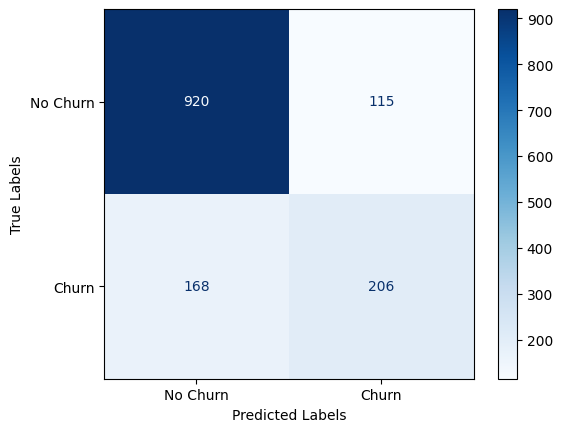

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

----------------------------------------
ROC AUC score:
0.72

----------------------------------------


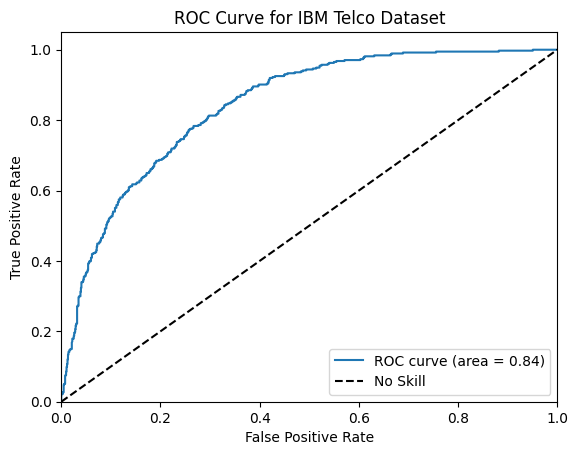

Accuracy Score:
0.80


In [18]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, confusion_matrix , ConfusionMatrixDisplay , auc , roc_curve

print("Confusion Matrix:\n")

cm = confusion_matrix(y_test, y_pred)
print(cm)
print("-" * 40)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels = ["No Churn","Churn"])
disp.plot(cmap = plt.cm.Blues)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()


print("Classification Report:\n")

print(classification_report(y_test, y_pred))
print("-" * 40)

print("ROC AUC score:")

print(f"{roc_auc_score(y_test, y_pred):.2f}\n")
print("-" * 40)
y_pred_prob = reg_model.predict_proba(x_test)[:,1]

#Calculate the ROC Curve

fpr,tpr,thresholds  = roc_curve(y_test,y_pred_prob)
roc_auc = auc(fpr,tpr)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for IBM Telco Dataset')
plt.legend()
plt.show()

print("Accuracy Score:")
print(f"{accuracy_score(y_test, y_pred):.2f}")
